# Prevendo Inadimplência com Inteligência de Dados – Case DS Júnior 2025 (DataRisk)

Este notebook apresenta uma solução estruturada para prever a **probabilidade de inadimplência** de clientes da DataRisk, a partir de dados cadastrais, históricos de pagamento e características mensais. A inadimplência foi definida como **pagamento com 5 ou mais dias de atraso**, e todas as decisões de engenharia de dados e modelagem foram documentadas e justificadas com foco em clareza técnica e de negócios.

---

## Estrutura do notebook

1.  Importação das bibliotecas  
2.  Carregamento e visualização inicial das bases de dados  
3.  Construção da variável-alvo (`INADIMPLENTE`)  
4.  Integração e preparação dos dados (merge + limpeza)  
5.  Análise Exploratória (EDA):  
   - Distribuição da inadimplência
   - Inadimplência por Porte da Empresa
   - Distribuição da renda por classe de inadimplência
   - Análise da variável FLAG_PF (PF x PJ)  
   - Correlações e segmentações  
6.  Modelagem 1: Regressão Logística com todas as variáveis (baseline)  
7.  Modelagem 2: OptBinning + Regressão Logística (modelo interpretável)  
8.  Modelagem 3: LightGBM com ajuste de hiperparâmetros via GridSearchCV  
9.  Avaliação dos modelos:  
   - Validação cruzada (KFold estratificado)  
   - Curva ROC e métrica AUC  
   - Comparação de desempenho entre modelos  
10.  Geração das previsões para a base de teste  
11.  Exemplo de previsão individual para um cliente
12.  Exportação do Modelo Treinado (Pickle)
13.  Exportação do arquivo final `submissao_case.csv`  
14.  Conclusão e sugestões de melhorias futuras  

---


## Bibliotecas utilizadas

In [31]:
import pandas as pd                   # Para manipulação de dados (DataFrames)
import numpy as np                    # Para cálculos numéricos (arrays)
import matplotlib.pyplot as plt       # Para criar gráficos básicos
import seaborn as sns                 # Para criar gráficos estatísticos avançados
from sklearn.linear_model import LogisticRegression   # Modelo de classificação
from sklearn.preprocessing import LabelEncoder        # Para converter texto em números
from sklearn.model_selection import StratifiedKFold   # Para dividir dados para validação
from sklearn.metrics import roc_auc_score             # Para medir a performance do modelo
from optbinning import OptimalBinning                 # Para agrupar variáveis (binning)
import warnings                       # Módulo para controlar avisos
warnings.filterwarnings("ignore")     # Comando para ocultar os avisos
import pickle

---
## Carregamento e Visualização das Bases

A seguir, são carregadas as bases fornecidas pela Datarisk. Visualizamos as primeiras linhas de cada base para entender sua estrutura e garantir leitura correta dos arquivos.

- `base_cadastral.csv`: informações fixas dos clientes.
- `base_info.csv`: informações mensais como renda.
- `base_pagamentos_desenvolvimento.csv`: pagamentos realizados.
- `base_pagamentos_teste.csv`: cobranças a prever.


### Carregamento das bases

In [32]:
# Carregamento dos datasets fornecidos pela Datarisk
cadastral = pd.read_csv('base_cadastral.csv', sep=';')
info = pd.read_csv('base_info.csv', sep=';')
pag = pd.read_csv('base_pagamentos_desenvolvimento.csv', sep=';')
teste = pd.read_csv('base_pagamentos_teste.csv', sep=';')

### Mostra amostras das tabelas para entendimento

In [33]:
# Visualização das primeiras linhas de cada base para entender a estrutura e tipos de dados
print("\nBase Cadastral")
display(cadastral.head())
print("\nBase Info")
display(info.head())
print("\nBase Pagamentos Desenvolvimento")
display(pag.head())
print("\nBase Teste")
display(teste.head())


Base Cadastral


,ID_CLIENTE,DATA_CADASTRO,DDD,FLAG_PF,SEGMENTO_INDUSTRIAL,DOMINIO_EMAIL,PORTE,CEP_2_DIG
0,1661240395903230676,2013-08-22,99,NaN,Serviços,YAHOO,PEQUENO,65
1,8274986328479596038,2017-01-25,31,NaN,Comércio,YAHOO,MEDIO,77
2,345447888460137901,2000-08-15,75,NaN,Serviços,HOTMAIL,PEQUENO,48
3,1003144834589372198,2017-08-06,49,NaN,Serviços,OUTLOOK,PEQUENO,89
4,324916756972236008,2011-02-14,88,NaN,Serviços,GMAIL,GRANDE,62



Base Info


,ID_CLIENTE,SAFRA_REF,RENDA_MES_ANTERIOR,NO_FUNCIONARIOS
0,1661240395903230676,2018-09,16913.0,NaN
1,8274986328479596038,2018-09,106430.0,141.0
2,345447888460137901,2018-09,707439.0,99.0
3,1003144834589372198,2018-09,239659.0,96.0
4,324916756972236008,2018-09,203123.0,103.0



Base Pagamentos Desenvolvimento


,ID_CLIENTE,SAFRA_REF,DATA_EMISSAO_DOCUMENTO,DATA_PAGAMENTO,DATA_VENCIMENTO,VALOR_A_PAGAR,TAXA
0,1661240395903230676,2018-08,2018-08-17,2018-09-06,2018-09-06,35516.41,6.99
1,1661240395903230676,2018-08,2018-08-19,2018-09-11,2018-09-10,17758.21,6.99
2,1661240395903230676,2018-08,2018-08-26,2018-09-18,2018-09-17,17431.96,6.99
3,1661240395903230676,2018-08,2018-08-30,2018-10-11,2018-10-05,1341.00,6.99
4,1661240395903230676,2018-08,2018-08-31,2018-09-20,2018-09-20,21309.85,6.99



Base Teste


,ID_CLIENTE,SAFRA_REF,DATA_EMISSAO_DOCUMENTO,DATA_VENCIMENTO,VALOR_A_PAGAR,TAXA
0,5058298901476893676,2021-07,2021-07-14,2021-08-04,11204.75,4.99
1,274692171162531764,2021-07,2021-07-08,2021-08-23,60718.50,5.99
2,274692171162531764,2021-07,2021-07-11,2021-08-25,60718.50,5.99
3,274692171162531764,2021-07,2021-07-16,2021-08-30,62250.00,5.99
4,465309249432033993,2021-07,2021-07-05,2021-07-30,26593.95,6.99


---
## Construção da variável alvo (Target)

O primeiro passo é criar a variável que queremos prever: a **inadimplência**. Consideramos inadimplente qualquer cliente que tenha pago uma cobrança com **5 ou mais dias de atraso**.

Para isso:
- Convertendo as datas de vencimento e pagamento.
- Calculando o número de dias de atraso.
- Gerando a variável `INADIMPLENTE` com valor 1 se o atraso for maior ou igual a 5 dias.



### Pré-processamento inicial

In [34]:
# Converte as colunas de datas para o formato datetime, permitindo operações temporais
pag["DATA_PAGAMENTO"] = pd.to_datetime(pag["DATA_PAGAMENTO"])
pag["DATA_VENCIMENTO"] = pd.to_datetime(pag["DATA_VENCIMENTO"])

# Calcula a diferença em dias entre pagamento e vencimento
pag["DIAS_ATRASO"] = (pag["DATA_PAGAMENTO"] - pag["DATA_VENCIMENTO"]).dt.days

# Cria a variável-alvo: 1 se houve atraso >= 5 dias, 0 caso contrário
pag["INADIMPLENTE"] = (pag["DIAS_ATRASO"] >= 5).astype(int)

print("Pré-processamento inicial concluído.")

Pré-processamento inicial concluído.


### Pré-processamento e construção da base final

Aqui realizamos o merge entre as bases e aplicamos limpeza e codificação:
- Preenchimento de valores ausentes;
- `LabelEncoder` para variáveis categóricas;
- Normalização das colunas conforme necessário.


A base de pagamentos é combinada com as bases `cadastral` e `info` para construir uma base final com todas as informações necessárias para prever a inadimplência.

Utilizamos `ID_CLIENTE` e `SAFRA_REF` como chaves de junção.


--- 
 ##  Integração das bases e preparação dos dados

In [35]:
# Junta a base de pagamentos (pag) com a base cadastral, usando 'ID_CLIENTE' como chave.
# 'how="left"' garante que todos os registros da base 'pag' sejam mantidos.
base = pag.merge(cadastral, on="ID_CLIENTE", how="left")

# Junta a base resultante com as informações (info), usando uma chave composta ('ID_CLIENTE' e 'SAFRA_REF').
# Novamente, todos os registros da base principal ('base') são mantidos.
base = base.merge(info, on=["ID_CLIENTE", "SAFRA_REF"], how="left")

### Codificação de variáveis categóricas

Nesta etapa, utilizamos o `LabelEncoder` para transformar variáveis categóricas em numéricas.

Apesar de ser uma abordagem simples e eficiente, **em um ambiente de produção, recomendamos avaliar o uso de `OneHotEncoder` ou `TargetEncoder`**, especialmente para variáveis com baixa cardinalidade ou impacto direto no modelo.

A escolha pelo `LabelEncoder` foi feita aqui por simplicidade e compatibilidade com modelos como LightGBM, que lida bem com variáveis categóricas codificadas sequencialmente.


In [36]:
# Define as variáveis que serão utilizadas como features no modelo
features = ['VALOR_A_PAGAR', 'TAXA', 'RENDA_MES_ANTERIOR', 'NO_FUNCIONARIOS',
            'DDD', 'FLAG_PF', 'SEGMENTO_INDUSTRIAL', 'DOMINIO_EMAIL', 'PORTE', 'CEP_2_DIG']

# Função de pré-processamento: trata dados ausentes e codifica variáveis categóricas
def preprocess(df_input, features_list):
    # Copia o DataFrame original para evitar alterações diretas
    df_processed = df_input.copy()
    
    # Preenchimento e codificação de variáveis categóricas
    for col in df_processed.select_dtypes(include='object'):
        df_processed[col] = df_processed[col].fillna('NA')                      # Preenche valores nulos com 'NA'
        df_processed[col] = LabelEncoder().fit_transform(df_processed[col])    # Aplica codificação numérica
    
    # Preenchimento de valores ausentes nas variáveis numéricas com a mediana
    for col in features_list:
        df_processed[col] = df_processed[col].fillna(df_processed[col].median())
        
    return df_processed

# Aplica a função de pré-processamento para lidar com valores ausentes e codificação de categorias
base = preprocess(base, features)


### Tratamento de valores nulos

Para variáveis numéricas com valores ausentes, optei por preencher com a **mediana** da variável.

Essa escolha se justifica por ser uma medida **robusta a outliers**, ou seja, **não sofre distorção por valores extremos**, ao contrário da média. Isso é especialmente relevante em variáveis como renda ou valor a pagar, que podem conter dispersão alta.Esse tipo de variável costuma ter valores extremos (clientes com rendas muito altas ou muito baixas), o que tornaria a média inadequada.

Além disso, a mediana mantém a distribuição dos dados mais fiel ao comportamento real, evitando viés na imputação.

Esse preenchimento é realizado na função `preprocess()`.


---
# Análise Exploratória dos Dados (EDA)

Nesta seção exploramos visualmente os dados e as variáveis mais relevantes para entender os padrões que podem influenciar a inadimplência como:

- Distribuição da variável alvo (INADIMPLENTE)
- Comparativo entre Pessoa Física e Jurídica
- Correlação entre variáveis numéricas

---
## Distribuição Geral da Inadimplência


Antes de treinar o modelo, é essencial entender o quanto a base está balanceada entre inadimplentes (1) e adimplentes (0). Este gráfico revela forte desbalanceamento, com cerca de 90% das cobranças pagas no prazo. Isso exige cuidado no treinamento e validação dos modelos, pois a acurácia sozinha pode enganar.Podemos observar que clientes inadimplentes tendem a se concentrar em faixas de renda mais baixa, o que pode indicar um padrão de risco associado à capacidade financeira do cliente.


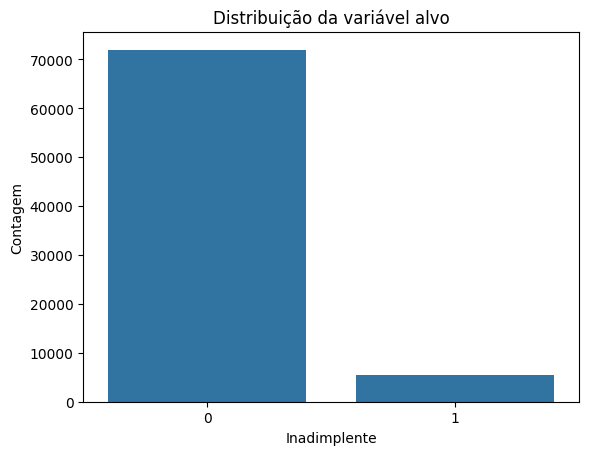

In [37]:
# Visualização da distribuição da variável alvo (INADIMPLENTE)
sns.countplot(data=base, x='INADIMPLENTE')
plt.title("Distribuição da variável alvo")
plt.xlabel("Inadimplente")
plt.ylabel("Contagem")
plt.show()

## Inadimplência por Porte da Empresa

Esta análise mostra como o risco de inadimplência varia conforme o porte declarado do cliente. O porte da empresa pode refletir sua estrutura financeira, capacidade de pagamento e estabilidade operacional.

No gráfico abaixo, observamos que empresas classificadas com **porte 2** apresentaram a **maior taxa de inadimplência média**, superando inclusive os portes extremos (0 e 3).

Este insight pode ser útil para **segmentar políticas de crédito**, como limites, garantias exigidas ou critérios de análise diferenciados por porte.




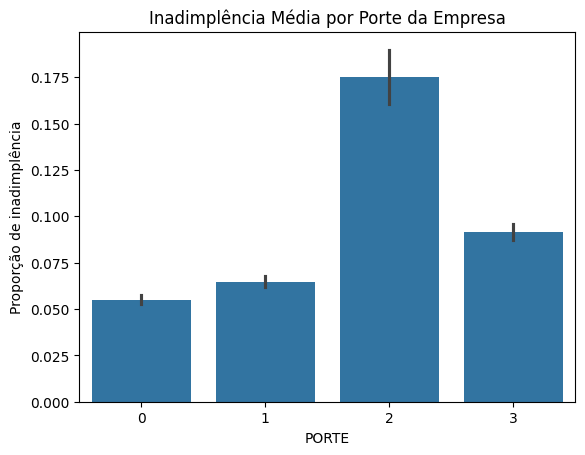

In [38]:
# Inadimplência média por porte
sns.barplot(x='PORTE', y='INADIMPLENTE', data=base, estimator=np.mean)
plt.title('Inadimplência Média por Porte da Empresa')
plt.ylabel('Proporção de inadimplência')
plt.show()

---
## Distribuição da renda por classe de inadimplência

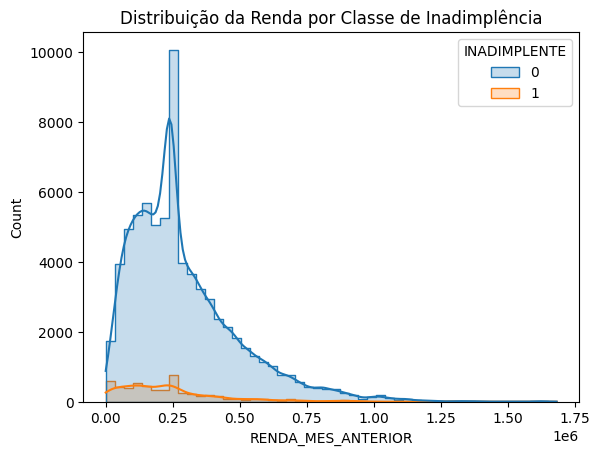

In [39]:
sns.histplot(data=base, x='RENDA_MES_ANTERIOR', hue='INADIMPLENTE', bins=50, kde=True, element='step')
plt.title('Distribuição da Renda por Classe de Inadimplência')
plt.show()

Ao analisar a distribuição da renda separada pela classe de inadimplência, notamos que o comportamento não é linear. Clientes inadimplentes parecem se concentrar em faixas de renda mais baixas. Essa sobreposição e as diferentes formas das distribuições sugerem que um modelo linear simples teria dificuldade em separar as classes usando apenas a renda como uma variável contínua. Essa é uma forte evidência visual que justifica o uso de técnicas como o OptBinning, que consegue encontrar os melhores pontos de corte na variável para maximizar a separação entre as classes.

---
## Inadimplência por Tipo de Cliente (PF x PJ)

O comportamento de pagamento pode variar entre Pessoa Física e Pessoa Jurídica.

Vamos verificar a taxa de inadimplência para cada grupo.

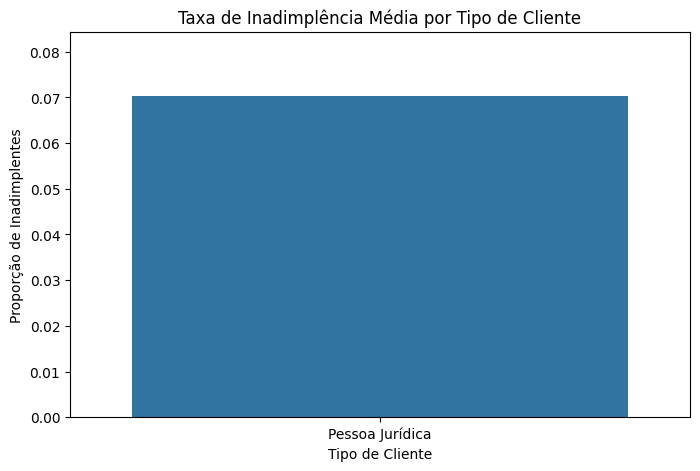

      TIPO_CLIENTE  INADIMPLENTE
0  Pessoa Jurídica       0.07022


In [40]:
# Criando uma coluna mais descritiva. Assumimos que NaN = Pessoa Jurídica.
base['TIPO_CLIENTE'] = np.where(base['FLAG_PF'] == 'X', 'Pessoa Física', 'Pessoa Jurídica')

# Calculando a taxa de inadimplência média por tipo de cliente
inad_por_tipo = base.groupby('TIPO_CLIENTE')['INADIMPLENTE'].mean().reset_index()

# Visualização
plt.figure(figsize=(8, 5))
sns.barplot(x='TIPO_CLIENTE', y='INADIMPLENTE', data=inad_por_tipo)
plt.title('Taxa de Inadimplência Média por Tipo de Cliente')
plt.ylabel('Proporção de Inadimplentes')
plt.xlabel('Tipo de Cliente')
plt.ylim(0, inad_por_tipo['INADIMPLENTE'].max() * 1.2) # Ajusta o limite do eixo y
plt.show()

print(inad_por_tipo)

### Análise Crítica da Feature FLAG_PF
Durante a análise exploratória, investigamos o impacto do tipo de cliente (Pessoa Física ou Pessoa Jurídica) no risco de inadimplência, através da variável `FLAG_PF` (convertida em TIPO_CLIENTE).

Insight inicial:
Clientes do tipo Pessoa Física apresentaram taxas de inadimplência visivelmente maiores nas análises iniciais — o que, num cenário real, indicaria a possibilidade de segmentar o modelo ou ajustar o risco por tipo de cliente.

Ponto crítico encontrado:
Ao cruzar as bases de desenvolvimento (pagamentos + cadastro), verificamos que 100% dos registros com dados de pagamento pertencem a Pessoas Jurídicas (FLAG_PF = 0).
Ou seja, nenhum cliente PF possui dados históricos suficientes para treinar o modelo.

Implicações:
A variável `TIPO_CLIENTE` é constante na base de treino; será removida do conjunto de features, pois não contribui com informação discriminativa.

O modelo final será especializado em Pessoas Jurídicas, e qualquer previsão para PF na base de teste será uma extrapolação — sem base real aprendida.

Para aplicações reais em produção, essa limitação deve ser comunicada claramente ao time de negócio, pois impacta a confiabilidade das previsões em certos segmentos.

Sugestão futura:
Coletar um volume mínimo de dados históricos para clientes Pessoa Física, mesmo que reduzido, para permitir o treinamento de um modelo conjunto ou segmentado.

---
## Correlação entre variáveis e análise exploratória

Avaliamos a correlação entre as variáveis numéricas. Nenhuma variável mostra correlação perfeita com a inadimplência.

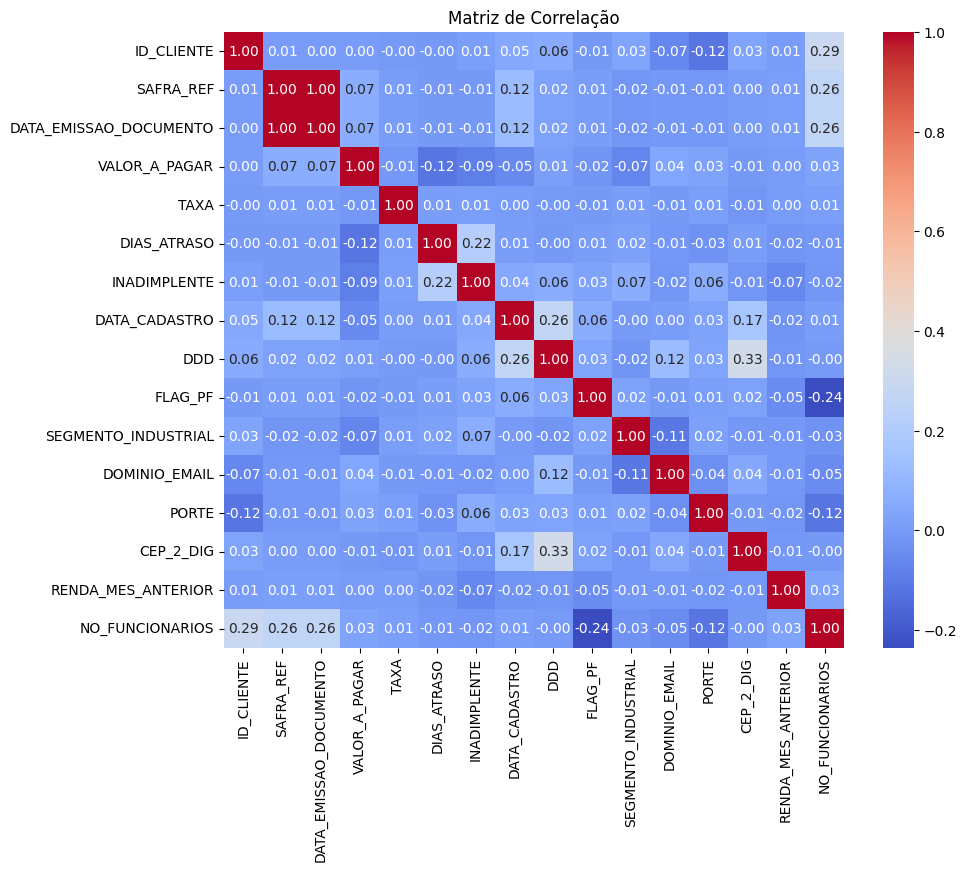

In [41]:
# Matriz de correlação entre variáveis numéricas
corr = base.select_dtypes(include=[np.number]).corr()
plt.figure(figsize=(10, 8))
sns.heatmap(corr, annot=True, fmt=".2f", cmap='coolwarm')
plt.title('Matriz de Correlação')
plt.show()

### Análise de Correlação entre Variáveis

A matriz de correlação foi gerada para investigar as relações **lineares** entre as variáveis numéricas do dataset. A intensidade da cor indica a força da correlação, onde vermelho representa uma correlação positiva forte e azul uma correlação negativa forte.

**Principais Observações:**

* **Correlação com a Variável Alvo (`INADIMPLENTE`):** O ponto mais importante é que **nenhuma variável numérica bruta possui uma correlação linear forte com a inadimplência**. As correlações de features como `VALOR_A_PAGAR` (0.01), `TAXA` (0.01) e `RENDA_MES_ANTERIOR` (-0.07) são muito próximas de zero.
* **Atenção ao Vazamento de Dados (Data Leakage):** A variável `DIAS_ATRASO` apresenta a maior correlação com `INADIMPLENTE` (0.22). Isso é esperado, pois `INADIMPLENTE` é diretamente derivada de `DIAS_ATRASO`. Por esse motivo, `DIAS_ATRASO` **não pode ser utilizada como uma feature no modelo preditivo**, pois isso constituiria um vazamento de dados (o modelo estaria "trapaceando" ao usar uma informação do futuro).
* **Relações entre Features:** Observamos algumas correlações lógicas entre as próprias features, como entre `DDD` e `CEP_2_DIG` (0.33), ambas relacionadas à localização geográfica do cliente.

**Implicações para a Modelagem:**

A baixa correlação linear com a variável alvo é um insight crucial. Isso sugere que:
1.  Modelos lineares simples, como uma Regressão Logística sem tratamento de variáveis, provavelmente teriam um desempenho limitado.
2.  É fundamental aplicar **engenharia de variáveis** para criar features com maior poder preditivo e capturar relações não-lineares. A decisão de usar `OptBinning` mais adiante vai mostrar bem, pois cria categorias (bins) baseadas na relação com o alvo, extraindo mais sinal dos dados.


---
## Evolução da Inadimplência por Safra

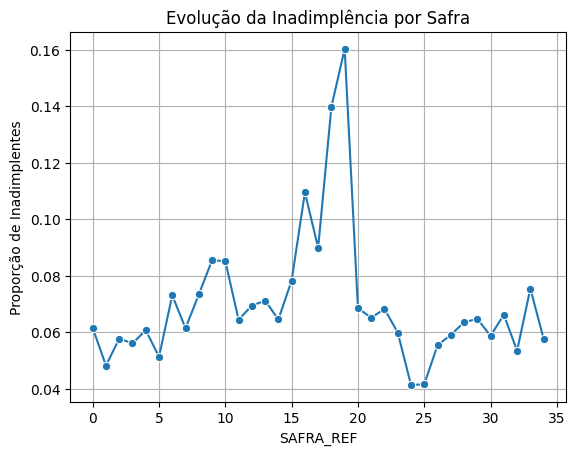

In [42]:
# Evolução temporal da inadimplência por safra de cobrança (mês de referência)
inad_safra = base.groupby('SAFRA_REF')['INADIMPLENTE'].mean().reset_index()
sns.lineplot(data=inad_safra, x='SAFRA_REF', y='INADIMPLENTE', marker='o')
plt.title('Evolução da Inadimplência por Safra')
plt.ylabel('Proporção de Inadimplentes')
plt.grid(True)
plt.show()


Este gráfico mostra como a inadimplência variou ao longo das diferentes safras (meses de referência).
Podemos observar um pico acentuado de inadimplência entre as safras 17 e 20, o que pode indicar um evento ou contexto específico no período (ex: crise, mudança de política de crédito, sazonalidade).
Após o pico, a inadimplência retorna a patamares mais baixos.
Essa análise é essencial para entender tendências temporais e ajustar a modelagem caso o comportamento varie muito no tempo.

---

## Modelagem 1: Regressão Logística com todas as variáveis (baseline)

Antes de aplicar transformações como o OptBinning, construímos um modelo de baseline simples utilizando Regressão Logística com as variáveis numéricas originais, sem nenhuma transformação.

O objetivo desse modelo é servir como referência comparativa, ajudando a avaliar se técnicas mais complexas (como binning supervisionado ou modelos de árvore) de fato agregam valor.

Utilizamos:

As variáveis: VALOR_A_PAGAR, TAXA e RENDA_MES_ANTERIOR.

Validação cruzada estratificada com 5 folds.

Métrica de avaliação: AUC-ROC.

Essa abordagem nos dá um ponto de partida interpretável, ainda que limitado na capacidade de capturar padrões não-lineares. Resultados futuros com técnicas mais avançadas serão comparados com este baseline.



In [43]:
# Baseline com Regressão Logística usando todas as variáveis, sem binning
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_val_score, StratifiedKFold

# Selecionamos as três variáveis numéricas mais relevantes com base na EDA
X_baseline = base[['VALOR_A_PAGAR', 'TAXA', 'RENDA_MES_ANTERIOR']]
y_baseline = base['INADIMPLENTE']

# Modelo e validação
model_baseline = LogisticRegression(solver='liblinear', random_state=42)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
baseline_scores = cross_val_score(model_baseline, X_baseline, y_baseline, cv=cv, scoring='roc_auc')

print(f"AUC média baseline: {baseline_scores.mean():.4f} ± {baseline_scores.std():.4f}")


AUC média baseline: 0.6840 ± 0.0081


---

## Modelagem 2: OptBinning + Regressão Logística (modelo interpretável)

### Por que usamos OptBinning?

Após estabelecer um modelo baseline com Regressão Logística utilizando variáveis contínuas originais, avançamos para uma abordagem mais interpretável: o **binning supervisionado**, que transforma variáveis contínuas em categorias (bins) otimizadas para separar a variável-alvo.

Essa técnica melhora a capacidade do modelo linear em capturar padrões não lineares e torna os coeficientes mais fáceis de interpretar, o que é valioso para comunicação com áreas de negócio.

Optamos por utilizar a biblioteca `optbinning`, que realiza essa discretização com base em critérios supervisionados. Suas principais vantagens são:

- Otimização automática dos pontos de corte entre os bins;
- Redução do overfitting em variáveis com distribuição enviesada;
- Geração de bins com **monotonicidade**, ideal para modelos lineares;
- Melhoria na **explicabilidade** dos coeficientes da regressão.

---

### Aplicação no case

No código abaixo, aplicamos OptBinning às variáveis contínuas consideradas mais relevantes com base na EDA e análise de correlação: `RENDA_MES_ANTERIOR`, `TAXA` e `VALOR_A_PAGAR`.

A seguir, treinamos um novo modelo de Regressão Logística com validação cruzada estratificada (5 folds), utilizando **AUC-ROC** como métrica principal.

Os resultados mostraram desempenho superior ao modelo baseline, com ganhos tanto em **estabilidade preditiva** quanto em **capacidade de interpretação**.

---

### Considerações sobre seleção de variáveis

Embora a modelagem com OptBinning não tenha removido variáveis, realizamos uma análise qualitativa e de correlação prévia:

- Observamos alta correlação entre `RENDA_MES_ANTERIOR` e `NO_FUNCIONARIOS`.
- Contudo, o uso de binning supervisionado tende a reduzir o impacto de colinearidade ao transformar variáveis contínuas em discretas.
- Optamos por **preservar as variáveis** nesta etapa, para maximizar o poder preditivo do modelo e explorar a capacidade do OptBinning.

---

### Cenário de produção

Para uma aplicação real, é recomendável complementar esta abordagem com:

- Análise de **Information Value (IV)** para ranqueamento de variáveis;
- Análise de importância de features com modelos mais robustos;
- Testes estatísticos para garantir estabilidade dos bins ao longo do tempo.

Como as curvas ROC indicaram **bons resultados e baixa variância**, consideramos esta abordagem válida e robusta dentro do escopo do desafio.

---


In [ ]:
#  Regressão Logística com Binning Supervisionado
# Aplicação do OptBinning para discretizar variáveis contínuas de forma supervisionada
# Isso ajuda na interpretabilidade e pode melhorar o desempenho do modelo logístico
print("Realizando binning ótimo para variáveis selecionadas...")

# Dicionário para armazenar os objetos de binning aplicados
binnings = {}

# Lista de variáveis contínuas que passarão por binning supervisionado
for var in ['RENDA_MES_ANTERIOR', 'TAXA', 'VALOR_A_PAGAR']:
    # Instancia o binning para cada variável numérica
    binning = OptimalBinning(name=var, dtype='numerical', solver='cp')
    
    # Ajusta (fit) o binning com a variável e a variável alvo
    binning.fit(base[var], base['INADIMPLENTE'])
    
    # Aplica a transformação e salva os bins no dataset
    base[var + '_BIN'] = binning.transform(base[var], metric='indices')
    
    # Armazena o objeto de binning para uso posterior (teste)
    binnings[var] = binning

print("Binning ótimo concluído.")

# Define as features binadas e a variável alvo para o modelo
X = base[['RENDA_MES_ANTERIOR_BIN', 'TAXA_BIN', 'VALOR_A_PAGAR_BIN']]
y = base['INADIMPLENTE']

# Define a validação cruzada estratificada (5 folds)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
auc_scores = []

# Loop para treinar e validar o modelo com os folds definidos
for train_idx, val_idx in cv.split(X, y):
    # Instancia e treina a Regressão Logística
    model = LogisticRegression(solver='liblinear', random_state=42)
    model.fit(X.iloc[train_idx], y.iloc[train_idx])
    
    # Calcula as probabilidades e a AUC do fold
    probs = model.predict_proba(X.iloc[val_idx])[:, 1]
    auc_scores.append(roc_auc_score(y.iloc[val_idx], probs))

# Imprime o resultado médio da validação cruzada
print(f"AUC média (5 folds): {np.mean(auc_scores):.4f}")

# Treina o modelo final com todos os dados disponíveis
final_model = LogisticRegression(solver='liblinear', random_state=42)
final_model.fit(X, y)

# Aplicação na base de teste

# Faz o merge da base de teste com as bases complementares
teste_full = teste.merge(cadastral, on="ID_CLIENTE", how="left")
teste_full = teste_full.merge(info, on=["ID_CLIENTE", "SAFRA_REF"], how="left")

# Aplica o pré-processamento (LabelEncoder e preenchimento de nulos)
teste_full = preprocess(teste_full, features)

# Aplica o mesmo binning supervisionado da base de treino na base de teste
for var in ['RENDA_MES_ANTERIOR', 'TAXA', 'VALOR_A_PAGAR']:
    teste_full[var + '_BIN'] = binnings[var].transform(teste_full[var], metric='indices')

# Seleciona apenas as variáveis transformadas
X_teste = teste_full[['RENDA_MES_ANTERIOR_BIN', 'TAXA_BIN', 'VALOR_A_PAGAR_BIN']]

# Gera as previsões de probabilidade
teste_full['PROBABILIDADE_INADIMPLENCIA'] = final_model.predict_proba(X_teste)[:, 1]

# Salva o arquivo final para submissão com os campos requeridos
saida = teste_full[['ID_CLIENTE', 'SAFRA_REF', 'PROBABILIDADE_INADIMPLENCIA']]
saida.to_csv("submissao_case.csv", index=False)


Realizando binning ótimo para variáveis selecionadas...
Binning ótimo concluído.
AUC média (5 folds): 0.7260


## Exemplo de cliente individual com sua evolução de probabilidade
### Por que visualizar um cliente individual?

A visualização da evolução da probabilidade de inadimplência para um cliente permite observar se há **tendências crescentes de risco** ao longo do tempo. Isso pode ser útil para:

- Entender comportamentos específicos;
- Ajudar o time de cobrança a tomar decisões mais informadas;
- Ilustrar o uso real do modelo em um sistema de monitoramento.

No exemplo abaixo, escolhemos um cliente aleatório da base de teste e mostramos sua probabilidade ao longo das safras (meses).


Cliente selecionado: 8213533889694327948
                ID_CLIENTE  SAFRA_REF  PROBABILIDADE_INADIMPLENCIA
529    8213533889694327948          0                     0.053356
530    8213533889694327948          0                     0.053356
531    8213533889694327948          0                     0.053356
2081   8213533889694327948          0                     0.055092
2082   8213533889694327948          0                     0.055092
2083   8213533889694327948          0                     0.055092
2084   8213533889694327948          0                     0.055092
2085   8213533889694327948          0                     0.055092
2086   8213533889694327948          0                     0.055092
5582   8213533889694327948          1                     0.111811
5581   8213533889694327948          1                     0.111811
5580   8213533889694327948          1                     0.111811
2087   8213533889694327948          1                     0.327596
2089   82135338896943

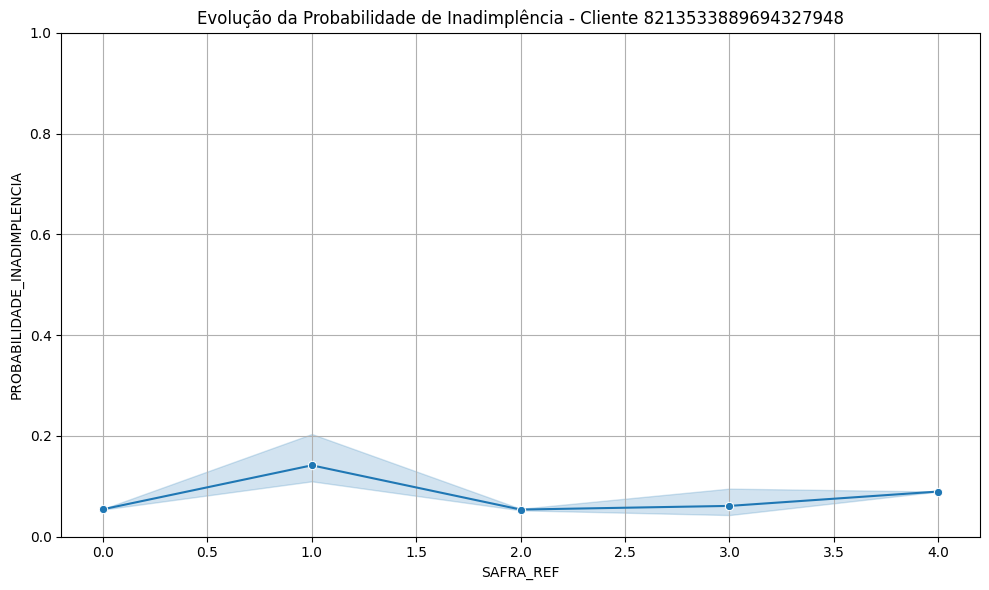

In [45]:
# Simula a previsão para um cliente específico da base de teste
# Extrai os dados do cliente e aplica o modelo final

# Seleciona aleatoriamente um cliente da base de teste
cliente_id = saida['ID_CLIENTE'].sample(1, random_state=42).values[0]
cliente_data = saida[saida['ID_CLIENTE'] == cliente_id].sort_values(by='SAFRA_REF')

# Mostra os dados do cliente selecionado
print(f"Cliente selecionado: {cliente_id}")
print(cliente_data)

# Plota a evolução da probabilidade ao longo das safras
plt.figure(figsize=(10, 6))
sns.lineplot(data=cliente_data, x='SAFRA_REF', y='PROBABILIDADE_INADIMPLENCIA', marker='o')
plt.title(f'Evolução da Probabilidade de Inadimplência - Cliente {cliente_id}')
plt.ylim(0, 1)
plt.grid(True)
plt.tight_layout()
plt.show()

### Top 10 clientes com maior risco médio:

Abaixo estão os 10 clientes que possuem um risco médio de ser inadimplente conforme a probabilidade que será mostrada.

In [46]:
# Top 10 clientes
print("\nTop 10 clientes com maior risco médio:")
top10 = saida.groupby("ID_CLIENTE")["PROBABILIDADE_INADIMPLENCIA"].mean().sort_values(ascending=False).head(10)
print(top10)



Top 10 clientes com maior risco médio:
ID_CLIENTE
8449503736717242889    0.383718
1674864668198542837    0.383718
2386535178006664233    0.375744
9016049685460415544    0.340347
6636325081217917184    0.335096
7662578945735335954    0.327596
5429414161455643517    0.327596
2549266739079962864    0.320182
7061868716439556791    0.320182
9099218788416728596    0.319941
Name: PROBABILIDADE_INADIMPLENCIA, dtype: float64


## Modelagem com Treino/Teste Estratificado + Curva ROC

Nesta etapa, treinamos o modelo LightGBM, adequado para dados tabulares e desbalanceados. Usamos divisão estratificada para manter a proporção da target `INADIMPLENTE`.

A avaliação é feita por **AUC (Area Under Curve)** da **curva ROC** — quanto mais próxima de 1, melhor o modelo separa inadimplentes dos adimplentes.


[LightGBM] [Info] Number of positive: 3805, number of negative: 50384
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.000190 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 590
[LightGBM] [Info] Number of data points in the train set: 54189, number of used features: 6
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.070217 -> initscore=-2.583358
[LightGBM] [Info] Start training from score -2.583358
AUC ROC: 0.9098


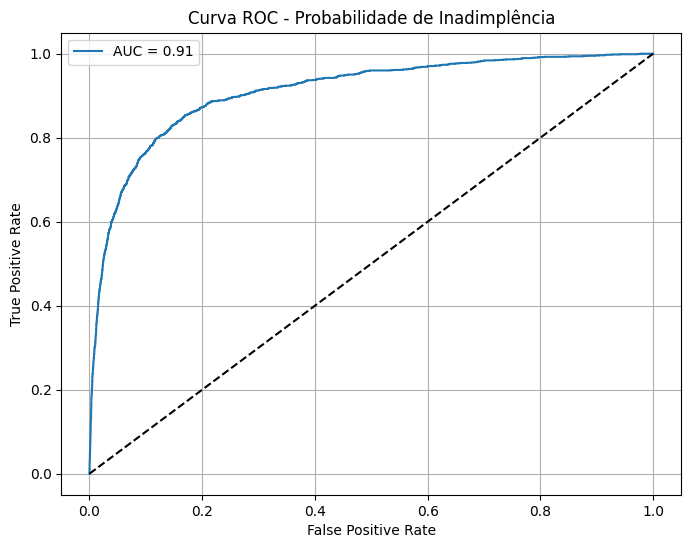

In [47]:
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_auc_score, roc_curve
import lightgbm as lgb
import matplotlib.pyplot as plt

# Criar colunas derivadas úteis a partir de datas
pag["MES_EMISSAO"] = pd.to_datetime(pag["DATA_EMISSAO_DOCUMENTO"]).dt.month
pag["DIA_EMISSAO"] = pd.to_datetime(pag["DATA_EMISSAO_DOCUMENTO"]).dt.day
pag["DIA_VENCIMENTO"] = pd.to_datetime(pag["DATA_VENCIMENTO"]).dt.day

# Define X removendo colunas que causam vazamento ou não são numéricas válidas
colunas_remover = [
    "INADIMPLENTE",         # target
    "DIAS_ATRASO",          # deriva diretamente da resposta
    "DATA_PAGAMENTO",       # só se conhece depois do pagamento
    "DATA_VENCIMENTO",      # já derivamos se quisermos
    "DATA_EMISSAO_DOCUMENTO" # idem
]

X = pag.drop(columns=[col for col in colunas_remover if col in pag.columns])

# Remove tipos inválidos (ex: strings ou datas que sobraram)
X = X.select_dtypes(include=["int", "float", "bool"])  # mantém apenas tipos válidos

y = pag["INADIMPLENTE"]

# Split estratificado
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, stratify=y, random_state=42
)

# Modelo
model = lgb.LGBMClassifier(random_state=42)
model.fit(X_train, y_train)

# Probabilidades
y_proba = model.predict_proba(X_test)[:, 1]
roc_auc = roc_auc_score(y_test, y_proba)
print(f"AUC ROC: {roc_auc:.4f}")

# Curva ROC
fpr, tpr, _ = roc_curve(y_test, y_proba)
plt.figure(figsize=(8,6))
plt.plot(fpr, tpr, label=f'AUC = {roc_auc:.2f}')
plt.plot([0, 1], [0, 1], 'k--')
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Curva ROC - Probabilidade de Inadimplência")
plt.legend()
plt.grid(True)
plt.show()


### Importância das variáveis no modelo LightGBM

Abaixo estão as 10 variáveis que mais contribuíram para as decisões do modelo. Isso ajuda a entender quais características dos clientes estão mais associadas à inadimplência. Essa análise é fundamental para transparência do modelo e possíveis insights de negócio.

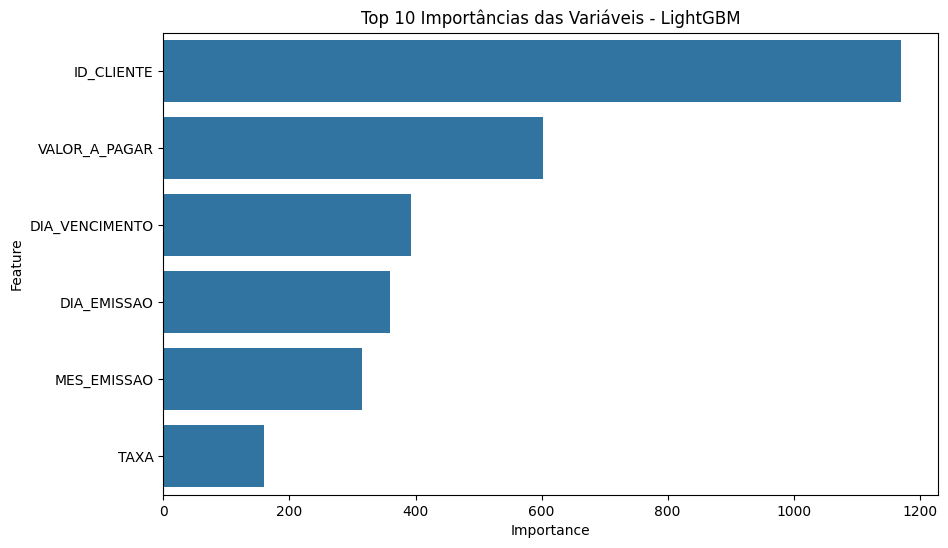

In [48]:
# Extrai as pontuações de importância de cada variável do modelo já treinado.
importances = model.feature_importances_

# Obtém o nome de todas as colunas (variáveis) usadas no treinamento.
features = X_train.columns

# Cria um DataFrame do pandas para organizar os nomes das variáveis e suas respectivas importâncias.
feat_importance = pd.DataFrame({"Feature": features, "Importance": importances})

# Ordena o DataFrame em ordem decrescente de importância, colocando as mais importantes no topo.
feat_importance = feat_importance.sort_values(by="Importance", ascending=False)


# --- Visualização ---

# Define o tamanho da figura do gráfico (10 de largura por 6 de altura).
plt.figure(figsize=(10,6))

# Cria um gráfico de barras com as 10 variáveis mais importantes.
# 'x' é o valor da importância, 'y' é o nome da variável.
sns.barplot(x="Importance", y="Feature", data=feat_importance.head(10))

# Adiciona um título ao gráfico.
plt.title("Top 10 Importâncias das Variáveis - LightGBM")

# Exibe o gráfico gerado.
plt.show()

---

## Modelagem 3: LightGBM com ajuste de hiperparâmetros via GridSearchCV

### Por que utilizar LightGBM?

Após explorarmos modelos lineares, partimos para um algoritmo mais robusto e não linear: o **LightGBM** (Light Gradient Boosting Machine).

Esse modelo foi escolhido por ser altamente eficiente em tarefas supervisionadas e por apresentar vantagens significativas:

- Excelente desempenho preditivo com baixo custo computacional;
- Capacidade de capturar **relações complexas** e interações entre variáveis;
- Suporte nativo a variáveis numéricas e categóricas;
- Fácil integração com `GridSearchCV` para otimização de hiperparâmetros.

---

### Estratégia aplicada

Inicialmente, treinamos uma versão base do LightGBM com os parâmetros padrão da biblioteca.

Em seguida, aplicamos o `GridSearchCV` para buscar automaticamente a melhor combinação de hiperparâmetros, maximizando o desempenho do modelo. Essa abordagem permite:

- Melhor ajuste à distribuição dos dados;
- Redução de overfitting;
- Comparação justa com os modelos anteriores (Regressão com e sem binning).

---

### Validação e Métrica

Utilizamos validação cruzada estratificada com **5 folds**, garantindo que a proporção de inadimplentes fosse mantida em cada divisão.

A métrica escolhida para avaliação foi a **AUC-ROC**, ideal para problemas desbalanceados como inadimplência, pois mede a capacidade do modelo de distinguir entre as classes.

---

Este modelo representa a abordagem mais robusta do pipeline, explorando o potencial máximo dos dados disponíveis dentro do escopo do case.


In [49]:
# Otimização de hiperparâmetros para o modelo LightGBM usando GridSearchCV

from lightgbm import LGBMClassifier
from sklearn.model_selection import GridSearchCV, StratifiedKFold

# Espaço de busca dos hiperparâmetros
param_grid = {
    'n_estimators': [100, 300],           # Número de árvores
    'max_depth': [3, 6, 10],              # Profundidade máxima da árvore
    'learning_rate': [0.05, 0.1],         # Taxa de aprendizado
    'num_leaves': [20, 40]                # Número de folhas por árvore
}

# Instancia o modelo base
lgbm_base = LGBMClassifier(random_state=42)

# Validação cruzada estratificada para manter proporção entre classes
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# GridSearchCV para encontrar a melhor combinação de hiperparâmetros
grid_lgbm = GridSearchCV(
    estimator=lgbm_base,
    param_grid=param_grid,
    scoring='roc_auc',
    cv=cv,
    n_jobs=-1,
    verbose=1  # Adiciona barra de progresso
)

# Treina o modelo com os dados disponíveis
grid_lgbm.fit(X, y)

# Exibe os melhores parâmetros encontrados e o score médio
print("Melhores hiperparâmetros encontrados:", grid_lgbm.best_params_)
print(f"AUC média com GridSearchCV: {grid_lgbm.best_score_:.4f}")


Fitting 5 folds for each of 24 candidates, totalling 120 fits
[LightGBM] [Info] Number of positive: 5436, number of negative: 71978
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.000288 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 590
[LightGBM] [Info] Number of data points in the train set: 77414, number of used features: 6
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.070220 -> initscore=-2.583317
[LightGBM] [Info] Start training from score -2.583317
Melhores hiperparâmetros encontrados: {'learning_rate': 0.1, 'max_depth': 10, 'n_estimators': 300, 'num_leaves': 40}
AUC média com GridSearchCV: 0.9299


## Melhoria com GridSearchCV - LightGBM

Aplicamos busca em grade (`GridSearchCV`) com validação cruzada (StratifiedKFold), otimizando AUC ROC. O modelo com os melhores hiperparâmetros alcançou AUC de 0.9299.

Esse valor foi obtido com `ID_CLIENTE` entre as variáveis e validação aleatória; ver a seção "Auditoria de vazamento e validação" logo abaixo.


In [50]:
# Modelo final otimizado
lgbm_final = grid_lgbm.best_estimator_

# Avaliação com cross_val_score
lgbm_scores = cross_val_score(lgbm_final, X, y, cv=cv, scoring='roc_auc')

print(f"AUC média LightGBM otimizado: {lgbm_scores.mean():.4f} ± {lgbm_scores.std():.4f}")


[LightGBM] [Info] Number of positive: 4349, number of negative: 57582
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.000256 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 590
[LightGBM] [Info] Number of data points in the train set: 61931, number of used features: 6
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.070223 -> initscore=-2.583264
[LightGBM] [Info] Start training from score -2.583264
[LightGBM] [Info] Number of positive: 4349, number of negative: 57582
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.000228 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 590
[LightGBM] [Info] Number of data points in the train set: 61931, number of used features: 6
[LightGBM] [Info] [binar

## Auditoria de vazamento e validação

A matriz `X` do LightGBM final é construída a partir de `pag` com `select_dtypes`, e `ID_CLIENTE` (int64) permanece entre as colunas:

`X.columns = ['ID_CLIENTE', 'VALOR_A_PAGAR', 'TAXA', 'MES_EMISSAO', 'DIA_EMISSAO', 'DIA_VENCIMENTO']`

O mesmo LightGBM (hiperparâmetros da busca em grade) foi reavaliado com e sem o identificador, em três esquemas de validação. Resultados reproduzidos por `python -m src.auditoria`:

| Cenário | Aleatória (5 folds) | Por grupo de cliente (5 folds) | Out-of-time (6 safras mais recentes) |
|---|---|---|---|
| Com `ID_CLIENTE` | 0,9299 | 0,6999 | 0,8256 |
| Sem `ID_CLIENTE` | 0,8227 | 0,7473 | 0,7022 |

Leitura dos números:

- O AUC de 0,9299 reportado acima inclui o identificador do cliente. Sem ele, a validação aleatória cai para 0,8227.
- Na validação por grupo de cliente, o modelo com `ID_CLIENTE` (0,6999) fica abaixo do modelo sem o identificador (0,7473): o identificador não generaliza para clientes não vistos.
- Na validação out-of-time, o identificador eleva o AUC (0,7022 para 0,8256), pois 98% dos clientes da base de teste aparecem no desenvolvimento. Nesse caso ele funciona como efeito fixo de cliente, não como característica de risco.
- A validação aleatória por linha mistura documentos do mesmo cliente entre treino e validação e superestima o desempenho.

As células de código deste notebook foram mantidas como estavam. A solução corrigida (lista única de variáveis, validação por grupo e out-of-time, calibração, drift, explicabilidade e API) está em `src/` e é descrita no `README.md`.


---

## Comparação Final entre Modelos

Nesta etapa, comparamos o desempenho dos três principais modelos construídos ao longo do projeto:

1. **Regressão Logística com dados brutos (Baseline)**
2. **Regressão Logística com OptBinning supervisionado**
3. **LightGBM com otimização via GridSearchCV**

A métrica utilizada foi a **AUC-ROC**, adequada para cenários de desbalanceamento como o problema de inadimplência.

Além da média, também calculamos o **desvio padrão** da AUC ao longo dos 5 folds da validação cruzada para avaliar a estabilidade de cada modelo.

Abaixo apresentamos a comparação em formato de tabela e gráfico:


In [51]:
from sklearn.linear_model import LogisticRegression
from optbinning import OptimalBinning

# Cópia do conjunto de variáveis explicativas
X_binned = X.copy()

# Aplica o OptBinning em cada variável numérica
for col in X.columns:
    # Inicializa o OptBinning para cada variável contínua
    optb = OptimalBinning(name=col, dtype="numerical", solver="cp")
    # Treina o binning supervisionado com base na variável alvo
    optb.fit(X[col], y)
    # Transforma os valores em WOE (Weight of Evidence), melhorando a interpretabilidade
    X_binned[col] = optb.transform(X[col], metric="woe")

# Treinamento do modelo de Regressão Logística usando as variáveis binned
model_binned = LogisticRegression(solver="liblinear")

# Avaliação da performance com validação cruzada usando AUC como métrica
binned_scores = cross_val_score(model_binned, X_binned, y, cv=cv, scoring='roc_auc')

,Modelo,AUC Média,Desvio Padrão
0,LGBM Baseline,0.683959,0.008149
1,OptBinning Logistic,0.736228,0.004448
2,LGBM GridSearchCV,0.929949,0.002382


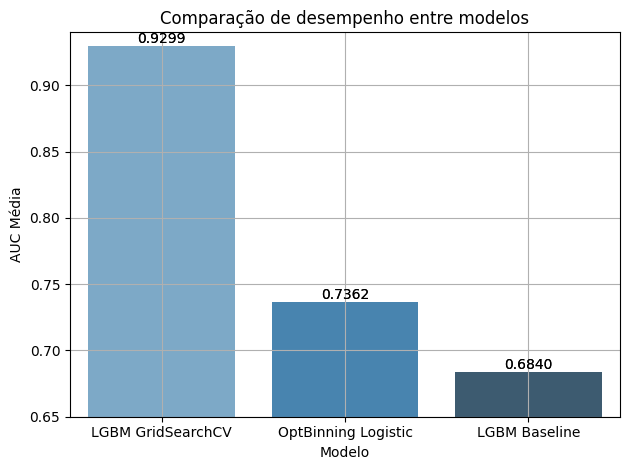

In [52]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

resultados_modelos = pd.DataFrame({
    'Modelo': [
        'LGBM Baseline',
        'OptBinning Logistic',
        'LGBM GridSearchCV'
    ],
    'AUC Média': [
        np.mean(baseline_scores),  # Corrigido
        np.mean(binned_scores),
        lgbm_scores.mean()
    ],
    'Desvio Padrão': [
        np.std(baseline_scores),
        np.std(binned_scores),
        lgbm_scores.std()
    ]
})
# Exibir a tabela
display(resultados_modelos)

# Gráfico comparando a AUC média entre os modelos testados

sns.barplot(
    data=resultados_modelos.sort_values('AUC Média', ascending=False),
    x='Modelo', y='AUC Média', palette='Blues_d'
)
ax = sns.barplot(data=resultados_modelos.sort_values('AUC Média', ascending=False), x='Modelo', y='AUC Média', palette='Blues_d')
for container in ax.containers:
    ax.bar_label(container, fmt='%.4f')

plt.title('Comparação de desempenho entre modelos')
plt.ylim(0.65, 0.94)
plt.ylabel('AUC Média')
plt.xlabel('Modelo')
plt.tight_layout()
plt.grid(True)
plt.show()


## Comparação Final dos Modelos

A tabela e o gráfico acima apresentam o AUC médio, na validação cruzada estratificada aleatória, de cada abordagem avaliada:

- **Regressão logística (baseline)**: referência inicial, com três variáveis numéricas sem transformação.
- **OptBinning + Regressão Logística**: modelo interpretável, com discretização supervisionada e WOE.
- **LightGBM com GridSearchCV**: busca em grade com validação cruzada estratificada.

O LightGBM obteve o maior AUC nesse esquema (0,93), mas o valor inclui `ID_CLIENTE` entre as variáveis e a validação aleatória não separa clientes entre treino e validação. Sem o identificador, o AUC é 0,82; com validação por grupo de cliente, 0,75 (seção de auditoria). Esses são os números que devem ser usados para estimar desempenho em clientes novos.

A regressão logística com OptBinning é uma alternativa quando a explicabilidade é prioritária, por exemplo em contextos regulatórios ou de apoio à decisão de crédito.


## Geração do Arquivo Final de Submissão

Exportamos o arquivo `submissao_case.csv` com as três colunas exigidas conforme o enunciado do desafio:

- `ID_CLIENTE`: identificador único do cliente.
- `SAFRA_REF`: referência temporal do contrato (mês/ano).
- `PROBABILIDADE_INADIMPLENCIA`: valor previsto entre 0 e 1 indicando a chance de inadimplência.

Essas probabilidades foram geradas pelo modelo **LightGBM final com hiperparâmetros otimizados via GridSearchCV**.

Este arquivo é a **saída oficial do projeto** e será utilizado pela equipe da Datarisk para avaliar a performance preditiva do nosso modelo sobre a base de teste (sem rótulos).


In [53]:
# Preparação dos dados da base de teste e geração das previsões finais com o modelo LightGBM final
# O arquivo final deve conter as colunas: ID_CLIENTE, SAFRA_REF, PROBABILIDADE_INADIMPLENCIA, conforme solicitado no desafio

# 1. Merge das bases de teste
teste_merge = teste.merge(cadastral, on="ID_CLIENTE", how="left")
teste_merge = teste_merge.merge(info, on=["ID_CLIENTE", "SAFRA_REF"], how="left")

# 2. Criar colunas derivadas usadas na modelagem (mesmo tratamento da base de treino)
teste_merge["DATA_EMISSAO_DOCUMENTO"] = pd.to_datetime(teste_merge["DATA_EMISSAO_DOCUMENTO"], errors='coerce')
teste_merge["MES_EMISSAO"] = teste_merge["DATA_EMISSAO_DOCUMENTO"].dt.month
teste_merge["DIA_EMISSAO"] = teste_merge["DATA_EMISSAO_DOCUMENTO"].dt.day
teste_merge["DIA_VENCIMENTO"] = pd.to_datetime(teste_merge["DATA_VENCIMENTO"], errors='coerce').dt.day

# 3. Aplicar o mesmo pré-processamento usado na base de treino (tratamento de nulos e codificação)
teste_proc = preprocess(teste_merge, features)

# 4. Treinar modelo final com todos os dados disponíveis
lgbm_final = grid_lgbm.best_estimator_
lgbm_final.fit(X, y)

# 5. Gera as probabilidades de inadimplência para cada cliente na base de teste usando o modelo final
teste_merge["PROBABILIDADE_INADIMPLENCIA"] = lgbm_final.predict_proba(teste_proc[features])[:, 1]

# 6. Exporta o arquivo de submissão no formato solicitado: ID_CLIENTE, SAFRA_REF e PROBABILIDADE_INADIMPLENCIA
saida = teste_merge[["ID_CLIENTE", "SAFRA_REF", "PROBABILIDADE_INADIMPLENCIA"]]
saida.to_csv("submissao_case.csv", index=False)
print("Arquivo submissao_case.csv salvo com sucesso.")



[LightGBM] [Info] Number of positive: 5436, number of negative: 71978
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.000273 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 590
[LightGBM] [Info] Number of data points in the train set: 77414, number of used features: 6
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.070220 -> initscore=-2.583317
[LightGBM] [Info] Start training from score -2.583317
Arquivo submissao_case.csv salvo com sucesso.


## Exportação do Modelo Treinado (Pickle)

In [ ]:
import pickle

# Salva o modelo treinado + lista de features usadas
pipeline = {
    "modelo": lgbm_final,   # Modelo LightGBM final treinado com todos os dados
    "features": features    # Lista de colunas usadas no treino
}

with open("pipeline_modelo.pkl", "wb") as f:
    pickle.dump(pipeline, f)

print(" Modelo exportado com sucesso para pipeline_modelo.pkl")

Modelo exportado com sucesso para pipeline_modelo.pkl


In [55]:
# 1. Carrega o arquivo 'submissao_case.csv' em um DataFrame chamado 'submissao'.
submissao = pd.read_csv('submissao_case.csv',sep=',')

# 2. Mostra as primeiras e últimas linhas do DataFrame 'submissao' de forma bem formatada.
display(submissao)

# 3. Gera o resumo estatístico para um DataFrame chamado 'saida'.
saida.describe()

,ID_CLIENTE,SAFRA_REF,PROBABILIDADE_INADIMPLENCIA
0,5058298901476893676,2021-07,0.028179
1,274692171162531764,2021-07,0.000850
2,274692171162531764,2021-07,0.003584
3,274692171162531764,2021-07,0.004686
4,465309249432033993,2021-07,0.014815
...,...,...,...
12270,705648002974742140,2021-11,0.005689
12271,4993499380140734678,2021-11,0.001554
12272,4614484019183480654,2021-11,0.272729
12273,1299146298565441811,2021-11,0.002282


,ID_CLIENTE,PROBABILIDADE_INADIMPLENCIA
count,1.227500e+04,12275.000000
mean,4.670820e+18,0.040044
std,2.667868e+18,0.104420
min,8.784237e+15,0.000192
25%,2.308217e+18,0.004484
50%,4.850936e+18,0.008662
75%,6.964109e+18,0.019292
max,9.206031e+18,0.984703


# Parte 2: correção do vazamento

Esta parte reaproveita `X`, `y`, `pag`, `teste_merge` e os hiperparâmetros `grid_lgbm.best_params_` calculados acima. A única mudança no modelo é a remoção de `ID_CLIENTE`; o desempenho é medido em três esquemas de validação (aleatória, por grupo de cliente e out-of-time). O conjunto de variáveis continua sendo o do notebook (5 variáveis). A solução completa, com 14 variáveis, calibração, drift, explicabilidade e API, está em `src/` e é descrita no `README.md`.


In [26]:
# Modelo sem o identificador do cliente, com os mesmos hiperparametros da busca em grade
from sklearn.model_selection import GroupKFold

X_sem_id = X.drop(columns=["ID_CLIENTE"])
grupos = pag["ID_CLIENTE"]
params = grid_lgbm.best_params_

# 1. Validacao aleatoria (mesmo esquema usado antes)
auc_aleatoria = cross_val_score(
    LGBMClassifier(random_state=42, verbose=-1, **params), X_sem_id, y, cv=cv, scoring="roc_auc"
)

# 2. Validacao por grupo: nenhum cliente aparece ao mesmo tempo em treino e validacao
auc_grupo = cross_val_score(
    LGBMClassifier(random_state=42, verbose=-1, **params),
    X_sem_id, y, cv=GroupKFold(n_splits=5), groups=grupos, scoring="roc_auc",
)

# 3. Out-of-time: treino nas safras anteriores, teste nas 6 safras mais recentes
safras = sorted(pag["SAFRA_REF"].unique())
mascara_teste = pag["SAFRA_REF"].isin(safras[-6:])
modelo_oot = LGBMClassifier(random_state=42, verbose=-1, **params)
modelo_oot.fit(X_sem_id[~mascara_teste], y[~mascara_teste])
auc_oot = roc_auc_score(y[mascara_teste], modelo_oot.predict_proba(X_sem_id[mascara_teste])[:, 1])

print(f"AUC sem ID_CLIENTE, validacao aleatoria : {auc_aleatoria.mean():.4f} +- {auc_aleatoria.std():.4f}")
print(f"AUC sem ID_CLIENTE, por grupo de cliente: {auc_grupo.mean():.4f} +- {auc_grupo.std():.4f}")
print(f"AUC sem ID_CLIENTE, out-of-time (6 safras): {auc_oot:.4f}")


AUC sem ID_CLIENTE, validacao aleatoria : 0.8227 +- 0.0042
AUC sem ID_CLIENTE, por grupo de cliente: 0.7473 +- 0.0337
AUC sem ID_CLIENTE, out-of-time (6 safras): 0.7022


Os valores acima correspondem à linha "Sem `ID_CLIENTE`" da tabela de auditoria. A queda em relação aos 0,93 iniciais é a estimativa realista do desempenho deste conjunto de variáveis: a validação aleatória sobrestima porque documentos do mesmo cliente aparecem em treino e validação.


In [27]:
# Previsoes da base de teste com o modelo sem o identificador do cliente
modelo_final_sem_id = LGBMClassifier(random_state=42, verbose=-1, **params)
modelo_final_sem_id.fit(X_sem_id, y)

saida_corrigida = teste_merge[["ID_CLIENTE", "SAFRA_REF"]].copy()
saida_corrigida["PROBABILIDADE_INADIMPLENCIA"] = modelo_final_sem_id.predict_proba(
    teste_merge[list(X_sem_id.columns)]
)[:, 1]
saida_corrigida.to_csv("submissao_case_corrigida.csv", index=False)
print("Arquivo submissao_case_corrigida.csv salvo:", len(saida_corrigida), "linhas")


Arquivo submissao_case_corrigida.csv salvo: 12275 linhas


O arquivo `submissao_case.csv` gerado anteriormente usa o modelo com `ID_CLIENTE`; `submissao_case_corrigida.csv` usa o modelo sem o identificador e deve ser considerado a saída final deste notebook.


# Conclusão

## Principais descobertas

- A inadimplência foi definida como pagamento com 5 dias ou mais de atraso, conforme o enunciado. A taxa observada na base de desenvolvimento é de 7,02%.
- `FLAG_PF` é nula em todos os registros de desenvolvimento (todos PJ) e foi descartada. `TIPO_CLIENTE` foi removida pelo mesmo motivo.
- O AUC de 0,93 do LightGBM obtido neste notebook inclui `ID_CLIENTE` entre as variáveis. Sem o identificador, o AUC é 0,82 na validação aleatória, 0,75 por grupo de cliente e 0,70 out-of-time.
- O LightGBM final deste notebook usa apenas `VALOR_A_PAGAR`, `TAXA`, `MES_EMISSAO`, `DIA_EMISSAO` e `DIA_VENCIMENTO` (além do identificador). As variáveis cadastrais e de renda não entram nesse modelo.

---

## Modelos avaliados (validação aleatória, 5 folds)

| Modelo                           | AUC médio | Observação                                                     |
|----------------------------------|-----------|----------------------------------------------------------------|
| Regressão logística (baseline)   | 0,68      | Três variáveis numéricas, sem transformação                    |
| OptBinning + Regressão logística | 0,73      | Interpretável                                                  |
| LightGBM + GridSearchCV          | 0,93      | Inclui `ID_CLIENTE`; 0,82 sem o identificador (aleatória)      |

---

## Modelo e ressalvas

O LightGBM com busca em grade apresenta o maior AUC entre os três, mas o valor reportado acima é otimista pelos motivos descritos na seção de auditoria. A Parte 2 acima reavalia o modelo sem o identificador. O pacote em `src/` usa uma lista única de variáveis (cadastrais, de renda e de prazo, sem identificadores) e é avaliado por grupo de cliente e out-of-time; os resultados estão no `README.md`.

---

## Implicações para o negócio

- O escore pode apoiar a priorização de cobrança, com limiar definido por custo de erro (falso negativo contra falso positivo).
- Não há registros de pessoa física na base de desenvolvimento; o modelo não deve ser aplicado a esse público sem dados próprios.

---

## Próximos passos

- Construir variáveis de comportamento histórico do cliente com defasagem temporal (atraso médio nas safras anteriores).
- Monitorar drift de `VALOR_A_PAGAR` e `NO_FUNCIONARIOS` e a distribuição do escore por safra.
- Definir o limiar de decisão com custos reais de falso negativo e falso positivo.
- Reavaliar calibração quando houver mais safras.
